# Predicting the Kit End Date

The problem : Before a product can be built, its parts have to be gathered. This is called the *kit phase*. For every order in `inference.parquet` I need to predict the date the kit will be finished (`kit_end`). Planners can then schedule production and promise realistic dates to customers.

My plan :
- I predict the number of days between `kit_start` and `kit_end`, then add that to `kit_start` to get the date.
- This is a regression problem, because the answer is a number of days.
- I check my model on the last five weeks of the training data, not on a random sample. The inference orders come *after* the training orders, so this is the fairest test.
- I compare the model against a simple rule that needs no machine learning (the company's own expected kit time). The model has to beat it to be worth using.
- I measure error as MAE: the average number of days my prediction is wrong by.

How the notebook is organised: I go through the five files one by one (read, check, clean, explore). Then I merge them into one table, build the model, and check it is reliable.

Assumptions I am making:
- The orders are from site KHO and the calendar is for site FCJ. as per email confirmation I am treating them as the same site.
- Capacity has repeated rows. I check they are identical and keep one row per date.
- Orders where `kit_end` is before `kit_start` are mistakes, so I leave them out of training and scoring.
- `est_ship_date` = 1900-01-01 is a placeholder for "no date", so I turn it into a missing value.
- Families that are missing from the expected-minutes file stay in the data with a "missing" flag. I cannot drop inference rows.
- The capacity numbers for a date are assumed to be known when we predict.

## 1. Setup

I import the libraries and set the folder where the files are.

In [1]:
import os
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)

DATA_DIR = Path(os.environ.get("DATA_DIR", r"/content/"))
OUT_DIR = Path(os.environ.get("OUT_DIR", "outputs"))
OUT_DIR.mkdir(exist_ok=True)

DAYS = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]

## 2. File 1: `expected_minutes.parquet`

This is a small lookup table. For each product family it gives the average minutes to build (`expected_build_minutes`), burn software on (`expected_burn_minutes`) and kit (`expected_kit_minutes`) one unit. It is the company's own idea of how long things should take, so I will use it for my simple baseline later.

First I read it and check for missing values and duplicates. The minute columns show up as `object` instead of numbers, which I will need to fix.

In [2]:
em_raw = pd.read_parquet(DATA_DIR / "expected_minutes.parquet")
print("Shape:", em_raw.shape)
print(em_raw.dtypes.to_string())
print("\nMissing values:", em_raw.isna().sum().to_dict())
print("Duplicate family names:", em_raw.family_desc.dropna().duplicated().sum())
em_raw.head()

Shape: (260, 4)
family_desc                  str
expected_build_minutes    object
expected_burn_minutes     object
expected_kit_minutes      object

Missing values: {'family_desc': 1, 'expected_build_minutes': 0, 'expected_burn_minutes': 31, 'expected_kit_minutes': 0}
Duplicate family names: 0


,family_desc,expected_build_minutes,expected_burn_minutes,expected_kit_minutes
0,HFSDTS UJ,94.9401,2071.8561,2155.7586
1,MZWFHFS AXFSWS,84.3857,1080.5524,1464.1714
2,MZWFHFS IXX,84.3857,1080.5524,1464.1714
3,SFANIFI UJ,296.6429,4330.5714,1895.2857
4,HTKKJJ RNQQ TJRWIXX,69.4976,1436.1106,2033.6107


**Cleaning.** One row has no `family_desc`, so it can never match an order and I drop it. I convert the minute columns to numbers. The 31 missing values in `expected_burn_minutes` stay missing, because burn time is not part of the kit phase and I do not want to guess numbers. I also check that each family appears only once, because a repeated family would create extra order rows when I merge later.

In [3]:
em = em_raw.dropna(subset=["family_desc"]).copy()
for c in ["expected_build_minutes", "expected_burn_minutes", "expected_kit_minutes"]:
    em[c] = pd.to_numeric(em[c])

assert em.family_desc.is_unique
print("Families after cleaning:", len(em))
em.describe().round(0)

Families after cleaning: 259


,expected_build_minutes,expected_burn_minutes,expected_kit_minutes
count,259.0,228.0,259.0
mean,203.0,4128.0,2140.0
std,708.0,10771.0,2198.0
min,9.0,293.0,368.0
25%,67.0,1376.0,1360.0
50%,85.0,2072.0,1686.0
75%,131.0,2693.0,2186.0
max,7713.0,85646.0,18700.0


The plots below show how `expected_kit_minutes` is spread across families, and whether kit minutes go up when build minutes go up.

My Observation:  The kit minutes are very uneven: the middle family is about 1,700 minutes but the largest is about 18,700, so I used a log scale. The three minute columns are only weakly related to each other (correlation about 0.3 to 0.4). Also, 255 of the 259 families share exactly the same three values with at least one other family. So the minutes look like they were set for groups of products, not measured for each family. I only keep `expected_kit_minutes`, since that is the kit phase.

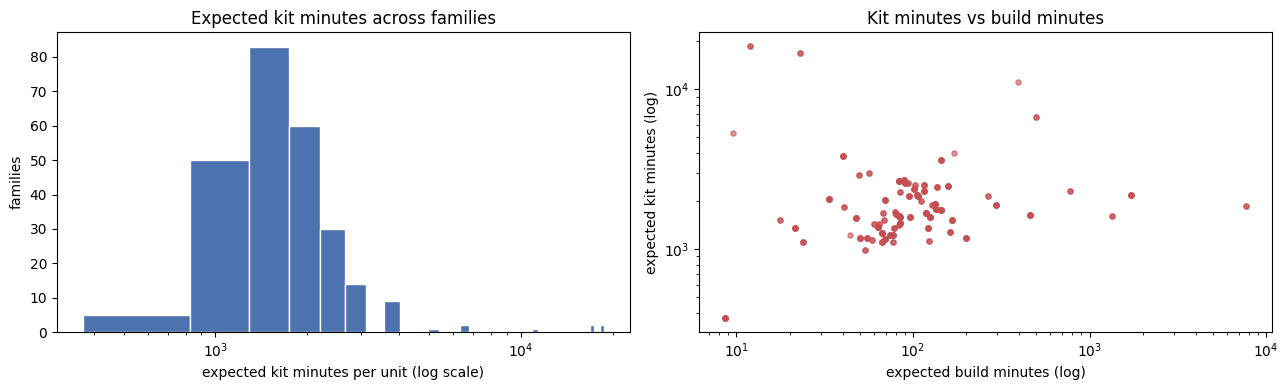

                        expected_build_minutes  expected_burn_minutes  expected_kit_minutes
expected_build_minutes                    1.00                   0.38                  0.32
expected_burn_minutes                     0.38                   1.00                  0.30
expected_kit_minutes                      0.32                   0.30                  1.00
Families sharing identical values with another family: 255 of 259


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].hist(em.expected_kit_minutes, bins=40, color="#4C72B0", edgecolor="white")
axes[0].set_xscale("log")
axes[0].set_xlabel("expected kit minutes per unit (log scale)"); axes[0].set_ylabel("families")
axes[0].set_title("Expected kit minutes across families")

axes[1].scatter(em.expected_build_minutes, em.expected_kit_minutes, s=14, alpha=0.6, color="#C44E52")
axes[1].set_xscale("log"); axes[1].set_yscale("log")
axes[1].set_xlabel("expected build minutes (log)"); axes[1].set_ylabel("expected kit minutes (log)")
axes[1].set_title("Kit minutes vs build minutes")
plt.tight_layout(); plt.show()

cols = ["expected_build_minutes", "expected_burn_minutes", "expected_kit_minutes"]
print(em[cols].corr(method="spearman").round(2).to_string())
print("Families sharing identical values with another family:", em.duplicated(subset=cols, keep=False).sum(), "of", len(em))

## 3. File 2: `calendar.parquet`

A table with one row per date. It has fiscal weeks and months and the flags `is_weekend` and `is_holiday`. It is for site FCJ, which we treat as the same as KHO.

For a calendar I check that there is exactly one row per date, no gaps, no missing values, and that `is_weekend` really matches Saturday and Sunday. The data dictionary says `day_of_week` runs from 1 to 7 with 1 as Saturday, so I do not use that column directly.

**Result.** The calendar covers 2025-03-06 to 2026-03-10 with no gaps or missing values, and `is_weekend` is exactly Saturday plus Sunday. There are 12 holidays. Nothing needs cleaning, so I keep it as it is. One small thing: the first orders start on 2025-03-04, two days before the calendar starts, so 5 orders will have no calendar row. I deal with that when merging.

In [5]:
cal_raw = pd.read_parquet(DATA_DIR / "calendar.parquet")
print("Rows:", len(cal_raw), "| unique dates:", cal_raw.date.nunique(), "| sites:", list(cal_raw.site.unique()))
print("Date range:", cal_raw.date.min().date(), "->", cal_raw.date.max().date())

all_days = pd.date_range(cal_raw.date.min(), cal_raw.date.max())
print("Missing dates in the range:", len(all_days.difference(pd.DatetimeIndex(cal_raw.date))))
print("Missing values:", int(cal_raw.isna().sum().sum()))

real_weekday = cal_raw.date.dt.dayofweek.map(dict(enumerate(DAYS)))
print("\nWeekday vs is_weekend flag:")
print(pd.crosstab(real_weekday.rename("weekday"), cal_raw.is_weekend).reindex(DAYS).to_string())
print("\nHolidays:", sorted(cal_raw[cal_raw.is_holiday == 1].date.dt.strftime("%Y-%m-%d")))

cal = cal_raw.copy()

Rows: 370 | unique dates: 370 | sites: ['FCJ']
Date range: 2025-03-06 -> 2026-03-10
Missing dates in the range: 0
Missing values: 0

Weekday vs is_weekend flag:
is_weekend   0   1
weekday           
Mon         53   0
Tue         53   0
Wed         52   0
Thu         53   0
Fri         53   0
Sat          0  53
Sun          0  53

Holidays: ['2025-05-27', '2025-07-04', '2025-09-02', '2025-11-28', '2025-11-29', '2025-12-23', '2025-12-24', '2025-12-25', '2025-12-26', '2025-12-27', '2026-01-01', '2026-01-15']


## 4. File 3: `capacity.parquet`

Daily factory capacity: `regular_hours`, `ot_hours` (overtime) and `ot_flag`. The data dictionary says the hours are based on `kit_start`, so I will join this table using the date an order starts kitting.

The file has about 192,000 rows, which is far too many for one row per day. So I check how many different records there really are, and whether any date has two different sets of numbers.

In [6]:
cap_raw = pd.read_parquet(DATA_DIR / "capacity.parquet")
print("Rows:", f"{len(cap_raw):,}", "| missing values:", cap_raw.isna().sum()[cap_raw.isna().sum() > 0].to_dict())

cap_dated = cap_raw.dropna(subset=["date"])
distinct = cap_dated.drop_duplicates()
print("Different records:", len(distinct), "| different dates:", distinct.date.nunique())

all_days = pd.date_range(distinct.date.min(), distinct.date.max())
print("Dates in the range with no record:", len(all_days.difference(pd.DatetimeIndex(distinct.date))))
print("Dates with zero regular hours:", sorted(distinct[distinct.regular_hours == 0].date.dt.strftime("%Y-%m-%d")))
print("Dates where ot_flag and ot_hours disagree:", int(((distinct.ot_flag == 1) != (distinct.ot_hours > 0)).sum()))

Rows: 191,934 | missing values: {'date': 12}
Different records: 317 | different dates: 317
Dates in the range with no record: 52
Dates with zero regular hours: ['2025-03-04', '2025-03-06', '2025-04-18']
Dates where ot_flag and ot_hours disagree: 1


**Cleaning.** Only 317 different records exist and each date has exactly one, so the repeats are just copies. I drop the 12 rows with no date and keep one row per date. Three dates have zero regular hours (probably closed days) and one date has an `ot_flag` that disagrees with `ot_hours`. I leave those alone and use the hours rather than the flag. 52 dates in the range have no record, which I check later when merging.

In [7]:
cap = distinct.copy()
assert cap.date.is_unique, "a date has two different capacity records"
print("Capacity table:", cap.shape, "(one row per date)")

Capacity table: (317, 4) (one row per date)


I looked at the average `regular_hours` and `ot_hours` for each weekday.

My Observation:  Monday to Friday run about 15 to 16 regular hours. Saturday and Sunday run only about 10.5 regular hours but a lot more overtime (about 7.5 hours). So capacity mostly follows the day of the week. I will test later whether it adds anything beyond the weekday itself.

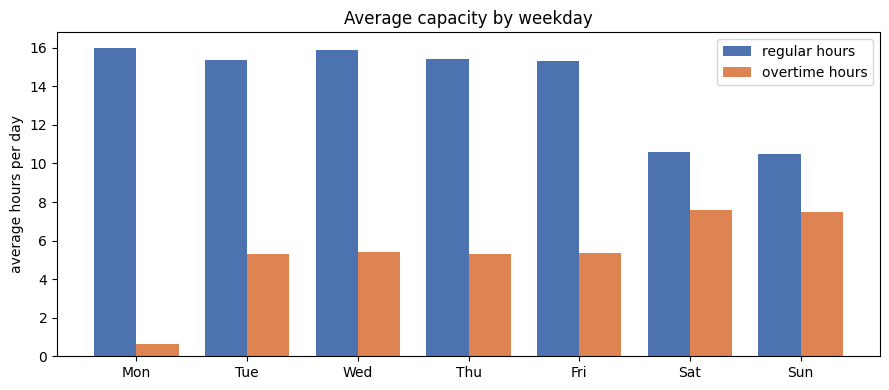

     regular_hours  ot_hours
Mon           16.0       0.7
Tue           15.4       5.3
Wed           15.9       5.4
Thu           15.4       5.3
Fri           15.3       5.4
Sat           10.6       7.6
Sun           10.5       7.5


In [8]:
cap_dow = cap.assign(dow=cap.date.dt.dayofweek).groupby("dow")[["regular_hours", "ot_hours"]].mean()
x = np.arange(7); w = 0.38

fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(x - w / 2, cap_dow.regular_hours.values, w, label="regular hours", color="#4C72B0")
ax.bar(x + w / 2, cap_dow.ot_hours.values, w, label="overtime hours", color="#DD8452")
ax.set_xticks(x); ax.set_xticklabels(DAYS); ax.set_ylabel("average hours per day")
ax.set_title("Average capacity by weekday"); ax.legend()
plt.tight_layout(); plt.show()
print(cap_dow.round(1).set_axis(DAYS).to_string())

## 5. File 4: `train.parquet`

This is the main file: one row per order line, with the dates of each stage. It is the only file that has the answer (`kit_end`), so it is the only one the model can learn from.

I start by reading it and checking missing values, data types, repeated keys and columns that never change.

In [9]:
train_raw = pd.read_parquet(DATA_DIR / "train.parquet")
print("Shape:", train_raw.shape)

nulls = train_raw.isna().sum()
print("Missing values:", nulls[nulls > 0].to_dict())
print("Repeated (sales_order_id, family_desc) pairs:", train_raw.duplicated(["sales_order_id", "family_desc"]).sum())
print("Columns with only one value:", [c for c in train_raw.columns if train_raw[c].nunique() == 1])
print("Type of a quantity_produced value:", type(train_raw.quantity_produced.iloc[0]).__name__)
train_raw.head(3)

Shape: (179853, 19)
Missing values: {'download_date': 5}
Repeated (sales_order_id, family_desc) pairs: 10
Columns with only one value: ['site', 'alt_type_desc']
Type of a quantity_produced value: Decimal


,sales_order_id,buid,site,orig_wo_id,tie_num,mcid,order_amt,quantity_produced,line_qty,cfs_flag,is_cfi,alt_type_desc,lob_desc,family_parent_desc,family_desc,download_date,kit_start,kit_end,est_ship_date
0,1025548771,11,KHO,22067915245,1,3JU,42935.31840,8,8,0,1,NSYJLWFYJI XTQZYNTSX LWTZU UGZ,UTBJWJILJ,LJSYWD,LJSYWD HXU,2025-10-15,2025-10-16,2025-10-17,2025-10-31
1,1027927868,11,KHO,22095717945,1,KHO,33128.74827,2,2,0,1,NSYJLWFYJI XTQZYNTSX LWTZU UGZ,UTBJWJILJ,HMFRUNTS,HMFRUNTS AXFSWS,2025-12-11,2025-12-12,2025-12-14,2026-03-16
2,1029939204,11,KHO,22112237255,1,KHO,17238.22614,1,1,0,1,NSYJLWFYJI XTQZYNTSX LWTZU UGZ,UTBJWJILJ,HMFRUNTS,HMFRUNTS UJ,2026-01-29,2026-01-30,2026-02-03,2026-06-17


**Cleaning the types and creating the target.** Four columns (`quantity_produced`, `line_qty`, `tie_num`, `buid`) are stored as `Decimal` objects, so I convert them to normal numbers. `site` and `alt_type_desc` have the same value in every row, so they cannot explain anything and I ignore them. Five rows have no `download_date` and ten rows repeat the key, which is too few to matter, so I leave them.

Then I create the target: `duration` = `kit_end` - `kit_start` in days.

In [10]:
def fix_types(d):
    d = d.copy()
    for c in ["quantity_produced", "line_qty", "tie_num", "buid"]:
        d[c] = d[c].astype(float)
    return d

train = fix_types(train_raw)
train["duration"] = (train.kit_end - train.kit_start).dt.days
print(train.duration.describe().round(2).to_string())

count    179853.00
mean          1.34
std           1.63
min         -25.00
25%           1.00
50%           1.00
75%           2.00
max          76.00


**Bad rows.** The smallest `duration` is negative, which is impossible because a kit cannot finish before it starts. There are 734 such rows (0.4%). The bad values are not random: they bunch up at about -11, -12 and -2 days, which looks like a systematic entry problem worth telling the business about. I leave them out of training and scoring but save a copy.

I also found `est_ship_date` = 1900-01-01 in 28 rows. That is a placeholder for "no date", so I set it to missing and keep those orders, since their target is fine.

In [11]:
invalid = train[train.duration < 0].copy()
print(f"Negative durations: {len(invalid)} rows ({len(invalid) / len(train):.2%})")
print("Most common bad values (days):", invalid.duration.value_counts().head(4).to_dict())

placeholder = train.est_ship_date.dt.year < 1950
print("Placeholder ship dates:", int(placeholder.sum()), "| of those, also negative:", int((placeholder & (train.duration < 0)).sum()))

invalid.to_parquet(OUT_DIR / "excluded_negative_duration.parquet")

train_clean = train[train.duration >= 0].copy()
train_clean.loc[train_clean.est_ship_date.dt.year < 1950, "est_ship_date"] = pd.NaT
train_clean["dow"] = train_clean.kit_start.dt.dayofweek      # 0 = Monday

print(f"Rows kept: {len(train_clean):,} of {len(train):,}")

Negative durations: 734 rows (0.41%)
Most common bad values (days): {-11: 278, -12: 209, -2: 120, -25: 51}
Placeholder ship dates: 28 | of those, also negative: 0


Rows kept: 179,119 of 179,853


### Exploring the target and the main features

As per my observations, most kits finish within a day or two. The middle value is 1 day, 68% finish within a day, and only 2% take 5 days or more (the longest is 76 days). So most orders are easy to predict, and my errors will be small fractions of a day. The few very long kits are what will be hard.

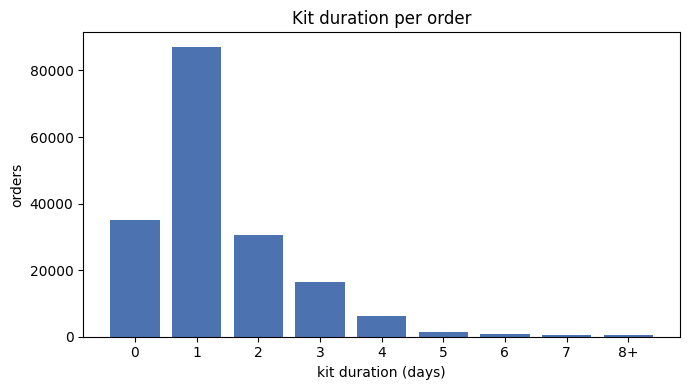

Finished within 1 day: 68% | 5+ days: 2.0%


In [12]:
fig, ax = plt.subplots(figsize=(7, 4))
counts = train_clean.duration.clip(upper=8).value_counts().sort_index()
ax.bar(counts.index, counts.values, color="#4C72B0")
ax.set_xticks(range(0, 9)); ax.set_xticklabels([str(i) for i in range(8)] + ["8+"])
ax.set_xlabel("kit duration (days)"); ax.set_ylabel("orders"); ax.set_title("Kit duration per order")
plt.tight_layout(); plt.show()

print(f"Finished within 1 day: {(train_clean.duration <= 1).mean():.0%} | 5+ days: {(train_clean.duration >= 5).mean():.1%}")

**Start weekday vs duration.** This turned out to be the most important feature. The factory starts about one in five kits on a **Saturday** and almost none on a Sunday. Kits that start Tuesday to Thursday take about 1.1 days on average, but kits that start on Saturday take about 2.1 days. Monday and Friday are in between.

This also tells me the calendar's `is_weekend` flag is not a good sign of when the factory is closed, because the factory is busy on Saturdays. So I use the real weekday instead.

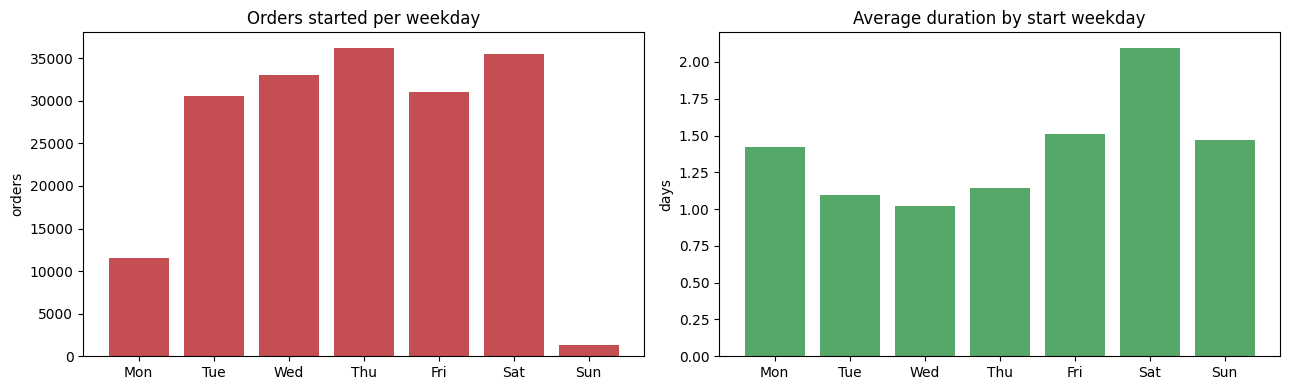

     mean  median  orders
Mon  1.42     1.0   11556
Tue  1.10     1.0   30553
Wed  1.02     1.0   32987
Thu  1.14     1.0   36219
Fri  1.51     1.0   31062
Sat  2.10     2.0   35441
Sun  1.47     1.0    1301


In [13]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

orders_by_dow = train_clean.groupby("dow").size()
axes[0].bar(DAYS, orders_by_dow.values, color="#C44E52")
axes[0].set_title("Orders started per weekday"); axes[0].set_ylabel("orders")

mean_by_dow = train_clean.groupby("dow").duration.mean()
axes[1].bar(DAYS, mean_by_dow.values, color="#55A868")
axes[1].set_title("Average duration by start weekday"); axes[1].set_ylabel("days")
plt.tight_layout(); plt.show()

print(train_clean.groupby("dow").duration.agg(mean="mean", median="median", orders="size").round(2).set_axis(DAYS).to_string())

I wanted to know if the work itself is slower, or if it is just the weekend getting in the way. So I compared the weekday on which orders **end**. About two thirds of Saturday starts end on Monday or Tuesday, and only about a quarter end during the weekend. This suggests the extra day is mostly the weekend gap (little work on Sunday), not slower kitting. This is my reading of the pattern, not something I can prove from the data.

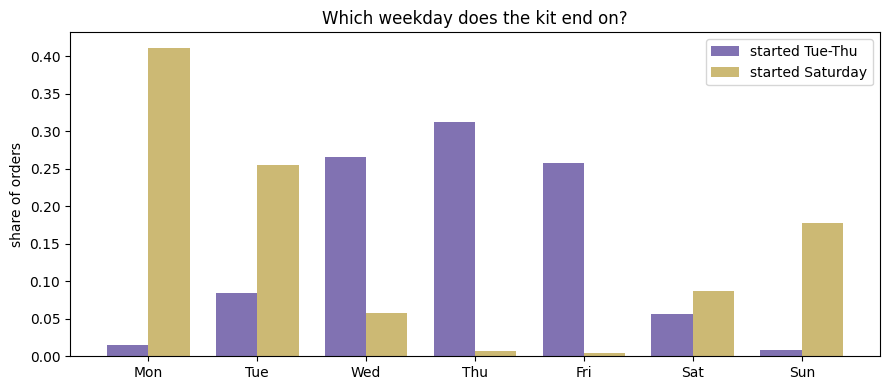

Saturday starts end on: {'Mon': '41%', 'Tue': '26%', 'Wed': '6%', 'Sat': '9%', 'Sun': '18%'}


In [14]:
sat_end = train_clean[train_clean.dow == 5].kit_end.dt.dayofweek.value_counts(normalize=True).reindex(range(7), fill_value=0)
mid_end = train_clean[train_clean.dow.isin([1, 2, 3])].kit_end.dt.dayofweek.value_counts(normalize=True).reindex(range(7), fill_value=0)

x = np.arange(7); w = 0.38
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(x - w / 2, mid_end.values, w, label="started Tue-Thu", color="#8172B2")
ax.bar(x + w / 2, sat_end.values, w, label="started Saturday", color="#CCB974")
ax.set_xticks(x); ax.set_xticklabels(DAYS)
ax.set_ylabel("share of orders"); ax.set_title("Which weekday does the kit end on?"); ax.legend()
plt.tight_layout(); plt.show()

print("Saturday starts end on:", {DAYS[i]: f"{v:.0%}" for i, v in sat_end.items() if v >= 0.05})

Trying to understand other columns as well. I checked the main ones against `duration`: `quantity_produced` (order size), `is_cfi` (software customisation), `mcid` (warehouse) and the waiting time between `download_date` and `kit_start`. If a column really mattered, the bars would clearly differ.

They mostly do not. Order size has no clear pattern and waiting time is not consistent (kits that start the same day as the download are the slowest, but longer waits do not mean longer kits). Software customisation adds a little (1.47 vs 1.30 days). A few warehouses are slower than KHO (for example KL3 at 2.0 days against 1.3), but the differences are small next to the weekday effect. `order_amt` and `cfs_flag` were also weak or flat. I test properly in section 9 whether adding any of these helps, instead of guessing.

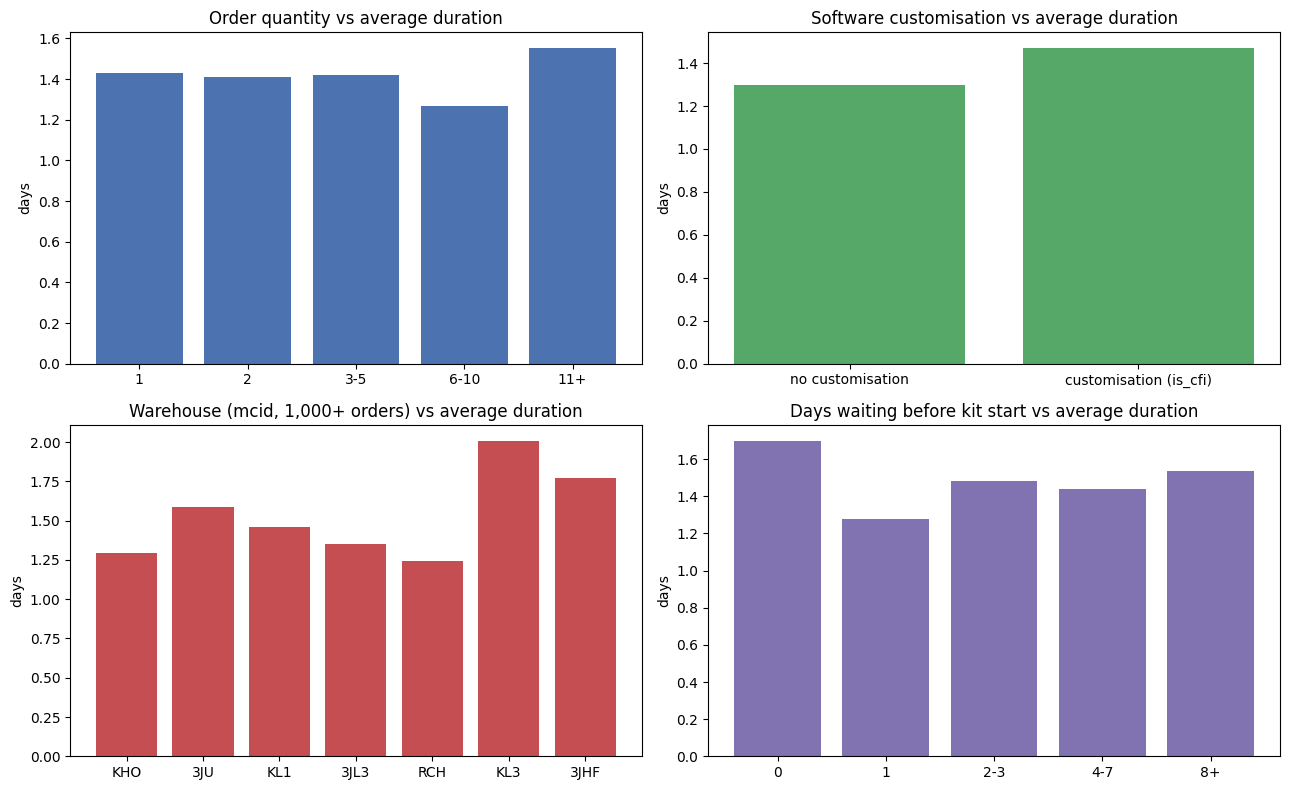

Correlation with duration:


quantity_produced   -0.037
order_amt            0.087
wait_days            0.031


In [15]:
d = train_clean.copy()
d["wait_days"] = (d.kit_start - d.download_date).dt.days

fig, axes = plt.subplots(2, 2, figsize=(13, 8))

q = d.groupby(pd.cut(d.quantity_produced, [-1, 1, 2, 5, 10, 100], labels=["1", "2", "3-5", "6-10", "11+"])).duration.mean()
axes[0, 0].bar(q.index.astype(str), q.values, color="#4C72B0")
axes[0, 0].set_title("Order quantity vs average duration"); axes[0, 0].set_ylabel("days")

c = d.groupby("is_cfi").duration.mean()
axes[0, 1].bar(["no customisation", "customisation (is_cfi)"], c.values, color="#55A868")
axes[0, 1].set_title("Software customisation vs average duration"); axes[0, 1].set_ylabel("days")

wh = d.groupby("mcid").duration.agg(["mean", "size"]).query("size >= 1000").sort_values("size", ascending=False)
axes[1, 0].bar(wh.index, wh["mean"].values, color="#C44E52")
axes[1, 0].set_title("Warehouse (mcid, 1,000+ orders) vs average duration"); axes[1, 0].set_ylabel("days")

wt = d.groupby(pd.cut(d.wait_days, [-1, 0, 1, 3, 7, 1000], labels=["0", "1", "2-3", "4-7", "8+"])).duration.mean()
axes[1, 1].bar(wt.index.astype(str), wt.values, color="#8172B2")
axes[1, 1].set_title("Days waiting before kit start vs average duration"); axes[1, 1].set_ylabel("days")
plt.tight_layout(); plt.show()

print("Correlation with duration:")
print(d[["duration", "quantity_produced", "order_amt", "wait_days"]].corr(method="spearman")["duration"].drop("duration").round(3).to_string())

As I will predict a later period, I checked whether `duration` drifts. It does. The first weeks of data (March 2025) were slow, at 2 to 3 days, which looks like a start-up period. Then mid-year was calm at about 1.0 to 1.2 days, and November to January ran higher at about 1.5 to 1.7 days. The share of kits taking 5+ days also crept up to about 3% in the last two months.

This is why I test on the latest weeks, and it means the model should be retrained from time to time.

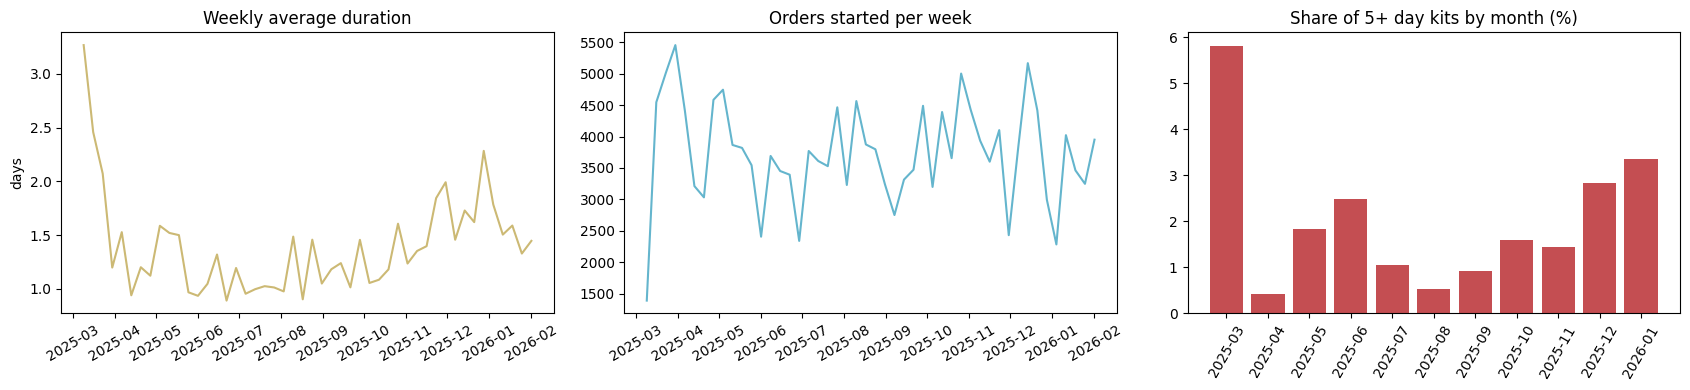

           avg_days  share_5plus_days  orders
kit_start                                    
2025-03       1.976             0.058   16692
2025-04       1.161             0.004   16756
2025-05       1.420             0.018   16572
2025-06       1.105             0.025   13004
2025-07       0.987             0.011   17996
2025-08       1.241             0.005   15956
2025-09       1.230             0.009   14869
2025-10       1.237             0.016   19212
2025-11       1.638             0.014   14685
2025-12       1.723             0.028   17679
2026-01       1.510             0.033   15698


In [16]:
weekly = train_clean.set_index("kit_start").duration.resample("W").agg(["mean", "size"])
monthly = train_clean.set_index("kit_start").assign(long_kit=lambda t: t.duration >= 5).resample("MS").agg(
    avg_days=("duration", "mean"), share_5plus_days=("long_kit", "mean"), orders=("duration", "size"))

fig, axes = plt.subplots(1, 3, figsize=(17, 4))
axes[0].plot(weekly.index, weekly["mean"], color="#CCB974")
axes[0].set_title("Weekly average duration"); axes[0].set_ylabel("days"); axes[0].tick_params(axis="x", rotation=30)
axes[1].plot(weekly.index, weekly["size"], color="#64B5CD")
axes[1].set_title("Orders started per week"); axes[1].tick_params(axis="x", rotation=30)
axes[2].bar(monthly.index.strftime("%Y-%m"), monthly.share_5plus_days.values * 100, color="#C44E52")
axes[2].set_title("Share of 5+ day kits by month (%)"); axes[2].tick_params(axis="x", rotation=60)
plt.tight_layout(); plt.show()

monthly.index = monthly.index.strftime("%Y-%m")
print(monthly.round(3).to_string())

## 6. File 5: `inference.parquet`

These are the orders I have to predict. It has the same columns as train but no `kit_end`. The rule here is different: **I must not drop any row**, because every order needs a prediction. I apply the same cleaning as for train (data types and the placeholder ship date), and check that the row count does not change.

In [17]:
inf_raw = pd.read_parquet(DATA_DIR / "inference.parquet")
print("Shape:", inf_raw.shape, "| has kit_end column:", "kit_end" in inf_raw.columns)

nulls = inf_raw.isna().sum()
print("Missing values:", nulls[nulls > 0].to_dict() or "none")
print("Repeated (sales_order_id, family_desc) pairs:", inf_raw.duplicated(["sales_order_id", "family_desc"]).sum())

inf = fix_types(inf_raw)
placeholder = inf.est_ship_date.dt.year < 1950
print("Placeholder ship dates set to missing:", int(placeholder.sum()))
inf.loc[placeholder, "est_ship_date"] = pd.NaT
inf["dow"] = inf.kit_start.dt.dayofweek

assert len(inf) == len(inf_raw), "rows were lost"

Shape: (12069, 18) | has kit_end column: False
Missing values: none
Repeated (sales_order_id, family_desc) pairs: 0
Placeholder ship dates set to missing: 1


A model only works well on new data if the new data looks similar. The inference orders start on 2026-02-03 or later, after the last train order (2026-01-31), so testing on the latest weeks of train is the right idea. Order sizes look the same, and almost every family (all but 0.08%) was seen in train.

But one thing is different: the weekday mix. Only about 7% of inference orders start on a Saturday (against about 20% in train), and about 4% start on a Sunday (under 1% in train). This matters in two ways. The average predicted duration will be lower than in train, which is fine. And Sunday starts are rare in the training data (about 1,300 rows), so predictions for them are less reliable.

train     kit_start: 2025-03-04 -> 2026-01-31
inference kit_start: 2026-02-03 -> 2026-03-07


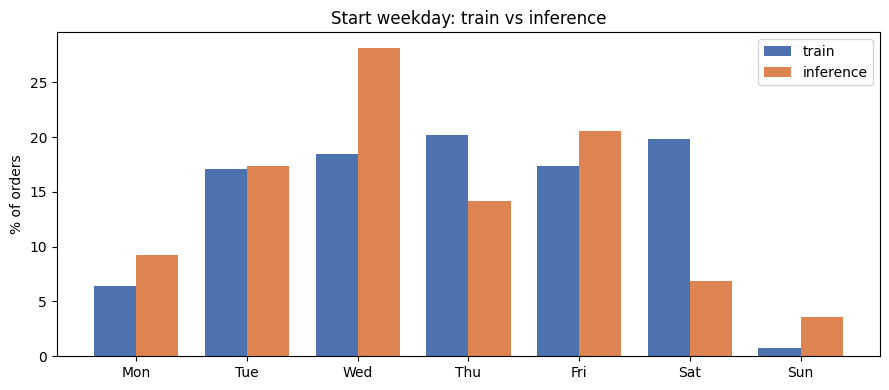

Median quantity: train 2.0 | inference 2.0


Families in inference never seen in train: 0.08%


In [18]:
print("train     kit_start:", train_clean.kit_start.min().date(), "->", train_clean.kit_start.max().date())
print("inference kit_start:", inf.kit_start.min().date(), "->", inf.kit_start.max().date())

mix = pd.DataFrame({"train": train_clean.dow.value_counts(normalize=True).sort_index(),
                    "inference": inf.dow.value_counts(normalize=True).sort_index()}).fillna(0)

fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(np.arange(7) - 0.19, mix.train.values * 100, 0.38, label="train", color="#4C72B0")
ax.bar(np.arange(7) + 0.19, mix.inference.values * 100, 0.38, label="inference", color="#DD8452")
ax.set_xticks(range(7)); ax.set_xticklabels(DAYS); ax.set_ylabel("% of orders")
ax.set_title("Start weekday: train vs inference"); ax.legend()
plt.tight_layout(); plt.show()

print("Median quantity: train", train_clean.quantity_produced.median(), "| inference", inf.quantity_produced.median())
print("Families in inference never seen in train:", f"{(~inf.family_desc.isin(train.family_desc)).mean():.2%}")

## 7. Merging the files into one main table

Now that I understand each file, I join them so there is **one row per order line**. This is what the model will learn from.

- `expected_minutes` is joined on `family_desc`, because minutes are given per family.
- `capacity` is joined on the `kit_start` date, because the data dictionary says the hours are based on `kit_start`.
- `calendar` is joined on the `kit_start` date for the same reason.

All joins start from the orders table and keep every order, even if there is no match. This matters most for inference, where I cannot lose rows. After each join I check the number of rows did not change. If a lookup table had a repeated key, the rows would silently multiply.

First, a question I had: why did the capacity file have so many repeated rows? My idea was that the capacity table had been joined to the orders before, giving one copy per order. If that is right, the number of raw capacity rows on a date should equal the number of orders that started that day.

In [19]:
orders_per_day = train.groupby("kit_start").size()
cap_rows_per_day = cap_raw.dropna(subset=["date"]).groupby("date").size()
check = pd.concat([orders_per_day, cap_rows_per_day], axis=1, keys=["train_orders", "raw_capacity_rows"]).dropna()

print("Dates compared:", len(check))
print("Dates where the two counts are equal:", int((check.train_orders == check.raw_capacity_rows).sum()))
check.head(3)

Dates compared: 289
Dates where the two counts are equal: 289


,train_orders,raw_capacity_rows
2025-03-04,5.0,5
2025-03-06,31.0,31
2025-03-07,390.0,390


The counts match on every date, so my idea was right. The capacity table was copied once per order. Keeping one row per date just undoes that, and it also shows that joining on `kit_start` is how the file was meant to be used.

Now the merge itself, with a row-count check after each join. At the end I print how many orders found a match in each table.

In [20]:
def build_master(orders):
    n0 = len(orders)

    out = orders.merge(em, on="family_desc", how="left")
    assert len(out) == n0, "expected_minutes join changed the row count"

    out = out.merge(cap, left_on="kit_start", right_on="date", how="left").drop(columns="date")
    assert len(out) == n0, "capacity join changed the row count"

    out = out.merge(cal[["date", "is_weekend", "is_holiday"]], left_on="kit_start", right_on="date", how="left").drop(columns="date")
    assert len(out) == n0, "calendar join changed the row count"
    return out

df = build_master(train_clean)
inf_master = build_master(inf)

print(f"Rows: train {len(df):,} (before {len(train_clean):,}) | inference {len(inf_master):,} (before {len(inf):,})")
match = pd.DataFrame({
    "train": [df.expected_kit_minutes.notna().mean(), df.regular_hours.notna().mean(), df.is_weekend.notna().mean()],
    "inference": [inf_master.expected_kit_minutes.notna().mean(), inf_master.regular_hours.notna().mean(), inf_master.is_weekend.notna().mean()],
}, index=["expected minutes matched", "capacity matched", "calendar matched"])
print("\nShare of orders with a match:")
print((match * 100).round(1).astype(str).add("%").to_string())

Rows: train 179,119 (before 179,119) | inference 12,069 (before 12,069)

Share of orders with a match:
                           train inference
expected minutes matched   75.5%     80.2%
capacity matched          100.0%    100.0%
calendar matched          100.0%    100.0%


**What the merge tells me**
- **Expected minutes:** only about 75% of train rows and 80% of inference rows have a family that is in the lookup. I tried fixing spaces and upper/lower case and no extra family matched, so these families really are missing from the file.
- **Capacity:** every order found a record, so the 52 dates with no capacity record are simply days with no orders.
- **Calendar:** 5 early train orders start before the calendar does. The calendar fully covers the inference period.

I do not want to drop the unmatched families, so I check whether those orders behave differently. I also check how often the factory starts kits on days the calendar calls a weekend.

In [21]:
miss = df.expected_kit_minutes.isna()
print("Average duration, family found    :", round(df[~miss].duration.mean(), 2))
print("Average duration, family not found:", round(df[miss].duration.mean(), 2))
print(f"\nKit starts on days the calendar calls a weekend: {df.is_weekend.mean():.1%}")
print(f"Kit starts on days with zero regular hours: {int((df.regular_hours == 0).sum())} of {len(df):,}")

Average duration, family found    : 1.37
Average duration, family not found: 1.44

Kit starts on days the calendar calls a weekend: 20.5%
Kit starts on days with zero regular hours: 46 of 179,119


**Decisions.**
- The unmatched families take about the same time as the others (1.44 vs 1.37 days). So I keep them and add a flag column `minutes_missing`, instead of dropping them or inventing numbers.
- About one in five kits starts on a day the calendar calls a weekend. So I use the real start weekday and the capacity hours, and I do not use `is_weekend` or `is_holiday`.

**Preparing the columns for the model.** The model needs numbers with no gaps. These are the columns I build:
- `start_Mon` to `start_Sun`: one 0/1 column for the weekday the kit starts.
- `regular_hours` and `ot_hours`: the capacity on the start date (filled with 0 if missing, which is rare).
- `expected_kit_minutes`: filled with the median of the training part when the family is missing.
- `minutes_missing`: 1 when the family was not in the lookup, so the model knows the value was filled.
- `quantity`: the number of units (from `quantity_produced`).

Any fill value, like that median, is worked out from the training part only, so nothing from the future leaks in.

In [22]:
def design(d, fill):
    X = pd.DataFrame(index=d.index)
    X["quantity"] = d.quantity_produced
    X["expected_kit_minutes"] = d.expected_kit_minutes.fillna(fill)
    X["minutes_missing"] = d.expected_kit_minutes.isna().astype(int)
    X["ot_hours"] = d.ot_hours.fillna(0)
    X["regular_hours"] = d.regular_hours.fillna(0)
    for k, name in enumerate(DAYS):
        X["start_" + name] = (d.dow == k).astype(float)
    return X

print("Main table: train", df.shape, "| inference", inf_master.shape)
df[["sales_order_id", "family_desc", "kit_start", "kit_end", "duration", "dow", "quantity_produced",
    "expected_kit_minutes", "regular_hours", "ot_hours"]].head()

Main table: train (179119, 29) | inference (12069, 27)


,sales_order_id,family_desc,kit_start,kit_end,duration,dow,quantity_produced,expected_kit_minutes,regular_hours,ot_hours
0,1025548771,LJSYWD HXU,2025-10-16,2025-10-17,1,3,8.0,2177.2297,16.0,5.5
1,1027927868,HMFRUNTS AXFSWS,2025-12-12,2025-12-14,2,4,2.0,1686.2296,16.0,5.5
2,1029939204,HMFRUNTS UJ,2026-01-30,2026-02-03,4,4,1.0,1686.2296,16.0,5.5
3,1023379512,RNZWF UJ,2025-11-29,2025-11-30,1,5,6.0,NaN,10.5,7.5
4,1017735495,MZWFHFS UJ,2025-04-03,2025-04-04,1,3,1.0,1464.1714,16.0,5.5


## 8. Train/test split, baseline and model

Before predicting the inference orders, I first test my model on some data it has not seen. I split the training data by time, not randomly. The last five weeks (from 2025-12-27) are my test set, which is about 10% of the data. Everything before that, about 90%, is used to train the model. I also left out the training orders that had not finished before the test period started, so the model does not use information from the future (about 1,200 orders).
I chose five weeks because the inference orders start about five weeks after the end of the training data, so this test is closest to the real situation.

In [23]:
CUT = pd.Timestamp("2025-12-27")
# Fix: ensure train orders have kit_end strictly before the validation period starts (no leakage)
is_train = (df.kit_start < CUT) & (df.kit_end < CUT)
is_val = (df.kit_start >= CUT)

fit, val = df[is_train], df[is_val]
yfit, yval = fit.duration, val.duration
print(f"fitting part: {len(fit):,} rows ({fit.kit_start.min().date()} -> {fit.kit_start.max().date()})")
print(f"test part   : {len(val):,} rows ({val.kit_start.min().date()} -> {val.kit_start.max().date()})")

def mae(y_true, y_pred):
    return float(np.mean(np.abs(np.asarray(y_true) - np.asarray(y_pred))))

fitting part: 160,656 rows (2025-03-04 -> 2025-12-24)
test part   : 17,241 rows (2025-12-27 -> 2026-01-31)


I wanted to understand how a prediction works without machine learning. I was already given an expected kit time for each family, so the simplest prediction is to turn it into days and round it:

predicted days = `expected_kit_minutes` / 1440, rounded

For families with no expected minutes I use the median duration of the fitting part. This is the score my model has to beat. I also show the score for always guessing the same number.

In [24]:
global_median = yfit.median()

def baseline_predict(d):
    return (d.expected_kit_minutes / 1440).round().fillna(global_median)

base_val = baseline_predict(val)
print(f"Baseline MAE: {mae(yval, base_val):.3f} days")
print(f"Always guessing {global_median:.0f} day: {mae(yval, global_median):.3f} days")

Baseline MAE: 0.814 days
Always guessing 1 day: 0.853 days


I chose linear regression as the model. I am predicting a number which is nothing but how many days a kit takes, and linear regression is simple and easy to explain. The earlier plots showed that most of what can be predicted comes from only a few features, mainly the start weekday, so linear regression handles that well. The inputs are the features I prepared in the previous sections. I round the predictions to whole days, because the real `duration` is always a whole number of days.

In [25]:
kit_median = fit.expected_kit_minutes.median()     # fill value from the fitting part only

model = LinearRegression().fit(design(fit, kit_median), yfit)
lin_val = np.maximum(np.round(model.predict(design(val, kit_median))), 0)    # whole days, never below 0

print(f"Linear regression MAE: {mae(yval, lin_val):.3f} days")
print(f"Baseline MAE         : {mae(yval, base_val):.3f} days")
print(f"Improvement          : {1 - mae(yval, lin_val) / mae(yval, base_val):.1%}")

Linear regression MAE: 0.737 days
Baseline MAE         : 0.814 days
Improvement          : 9.4%


First the average error for each start weekday. The model gains most on Saturday starts (error about 1.25 days down to 0.82), because the baseline has no idea the weekday matters. On Thursday and Friday the baseline is slightly better, so the model is not better everywhere. (There were no Sunday starts in this test period.)

Second, the error by actual duration. Kits that take 1 or 2 days are predicted well. Kits that finish the same day are over-predicted by about a day, because the model almost never predicts 0. Kits that take 5+ days are off by about 5 days. No model can catch these, because nothing in the data says why a kit is delayed .

In [26]:
by_dow = pd.DataFrame({
    "orders": val.groupby("dow").size(),
    "actual_mean_days": yval.groupby(val.dow).mean(),
    "predicted_mean_days": pd.Series(lin_val, index=val.index).groupby(val.dow).mean(),
    "baseline_MAE": pd.Series(np.abs(yval - base_val), index=val.index).groupby(val.dow).mean(),
    "model_MAE": pd.Series(np.abs(yval - lin_val), index=val.index).groupby(val.dow).mean(),
}).reindex(range(7)).round(2)
by_dow.index = DAYS
print(by_dow.to_string())

err = pd.DataFrame({"actual_days": yval.clip(upper=5).values, "abs_error": np.abs(yval.values - lin_val)})
by_actual = err.groupby("actual_days").agg(orders=("abs_error", "size"), model_MAE=("abs_error", "mean")).round(2)
by_actual.index = [str(i) if i < 5 else "5+" for i in by_actual.index]
print("\nError by actual duration:")
print(by_actual.to_string())

     orders  actual_mean_days  predicted_mean_days  baseline_MAE  model_MAE
Mon   923.0              1.74                 1.40          0.75       0.69
Tue  3161.0              0.92                 1.03          0.60       0.55
Wed  3973.0              1.34                 1.05          0.62       0.63
Thu  2675.0              1.44                 1.23          0.68       0.75
Fri  3273.0              1.55                 1.46          0.95       0.98
Sat  3236.0              2.31                 2.03          1.25       0.82
Sun     NaN               NaN                  NaN           NaN        NaN

Error by actual duration:
    orders  model_MAE
0     2861       1.11
1     8430       0.21
2     3013       0.47
3     1647       1.18
4      715       2.11
5+     575       5.08


## 9. Is the model reliable?
I also want to check if the remaining columns can improve the model on the test data. Here I add each column (is_cfi, cfs_flag, mcid, order_amt and the waiting days) to the model one at a time, and then all of them together. I check the MAE on the same test period each time. If a column helps, the error should go down.

In [27]:
def design_plus(d, fill, extras=()):
    X = design(d, fill)
    if "is_cfi" in extras:   X["is_cfi"] = d.is_cfi
    if "cfs_flag" in extras: X["cfs_flag"] = d.cfs_flag
    if "warehouse" in extras:
        for m in ["3JU", "KL1", "3JL3", "RCH", "KL3", "3JHF"]:
            X["wh_" + m] = (d.mcid == m).astype(float)
    if "log_amount" in extras: X["log_amount"] = np.log1p(d.order_amt)
    if "wait_days" in extras:
        X["wait_days"] = (d.kit_start - d.download_date).dt.days.fillna(1).clip(upper=30)
    return X

rows = []
for label, extras in [("current model", ()), ("+ is_cfi", ("is_cfi",)), ("+ cfs_flag", ("cfs_flag",)),
                      ("+ warehouse (mcid)", ("warehouse",)), ("+ order_amt (log)", ("log_amount",)),
                      ("+ waiting days", ("wait_days",)),
                      ("+ all of these", ("is_cfi", "cfs_flag", "warehouse", "log_amount", "wait_days"))]:
    m = LinearRegression().fit(design_plus(fit, kit_median, extras), yfit)
    p = np.maximum(np.round(m.predict(design_plus(val, kit_median, extras))), 0)
    rows.append({"model": label, "test_MAE": round(mae(yval, p), 3)})
pd.DataFrame(rows)

,model,test_MAE
0,current model,0.737
1,+ is_cfi,0.740
2,+ cfs_flag,0.738
3,+ warehouse (mcid),0.736
4,+ order_amt (log),0.744
5,+ waiting days,0.744
6,+ all of these,0.753


None of them improves the model, and adding them all makes it a bit worse. So I leave them out.

 I repeat the test on five separate five-week windows. Each time the model learns only from the data before the window and is scored on the window itself. The last window is the test period I used above. I also add a weekday only model, to see how much of the work is done by the weekday alone.

In [28]:
FEATURE_SETS = {
    "weekday only": [f"start_{d}" for d in DAYS],
    "final model (all columns)": list(design(df.head(5), 0).columns),
}

edges = pd.to_datetime(["2025-08-09", "2025-09-13", "2025-10-18", "2025-11-22", "2025-12-27", "2026-02-01"])
results = {}
for start, end in zip(edges[:-1], edges[1:]):
    # Fix leakage in validation loop by ensuring kit_end is strictly before the window
    a = df[(df.kit_start < start) & (df.kit_end < start)]
    b = df[(df.kit_start >= start) & (df.kit_start < end)]
    fill = a.expected_kit_minutes.median()
    Xa, Xb = design(a, fill), design(b, fill)

    row = {"orders": len(b),
           "always same number": mae(b.duration, a.duration.median()),
           "baseline (expected minutes)": mae(b.duration, baseline_predict(b).fillna(a.duration.median()))}
    for name, cols in FEATURE_SETS.items():
        m = LinearRegression().fit(Xa[cols], a.duration)
        row[name] = mae(b.duration, np.maximum(np.round(m.predict(Xb[cols])), 0))
    results[f"{start.date()}"] = row

rolling = pd.DataFrame(results)
rolling["average"] = rolling.drop(index="orders").mean(axis=1)
rolling.loc["orders", "average"] = np.nan
print("MAE in days for each window (the column name is the window start date):")
print(rolling.round(3).to_string())

fin = rolling.loc["final model (all columns)"].drop("average")
base = rolling.loc["baseline (expected minutes)"].drop("average")
print(f"\nFinal model beats the baseline in {int((fin < base).sum())} of {len(fin)} windows")
print(f"Average improvement: {1 - rolling.loc['final model (all columns)', 'average'] / rolling.loc['baseline (expected minutes)', 'average']:.1%}")

MAE in days for each window (the column name is the window start date):
                             2025-08-09  2025-09-13  2025-10-18  2025-11-22  2025-12-27  average
orders                        17201.000   18951.000   21198.000   19203.000   17241.000      NaN
always same number                0.602       0.590       0.799       1.029       0.853    0.775
baseline (expected minutes)       0.639       0.629       0.799       1.017       0.814    0.779
weekday only                      0.510       0.508       0.712       0.938       0.749    0.683
final model (all columns)         0.548       0.533       0.721       0.897       0.737    0.687

Final model beats the baseline in 5 of 5 windows
Average improvement: 11.8%


Observations from above experiment :
- The final model beats the company's baseline in all five windows. On average the error drops from 0.78 to 0.69 days, about 12% better.
- The baseline is no better than always guessing the same number (0.779 vs 0.775 days on average). So the company's expected kit times do not help much on their own.
- The weekday does most of the work. A weekday-only model already gets 0.683. Adding expected minutes, capacity and quantity does not improve the average (0.687 for the final model).

I keep the final model, but the weekday-only model does just as well (0.683 against 0.687), so the weekday is the main thing and the rest adds nothing. The weekday-only model also does not depend on the capacity data.

## 10. What this means for the business

MAE tells me the average number of days my prediction is off by, but a planner cares about different questions: *Will this order be done by the date I promise? How many orders will I get wrong?* So in this section I answer those questions in simple terms.

All numbers here come from the five-week test period, not from the inference orders. I look at:
- how often the prediction is exactly right, or within one day,
- how often an order finishes later than predicted, and how often it is 2 or more days later,
- how many orders per week this affects,
- how much of the total kit time comes from long kits (5 days or more) and from Saturday starts.

In [29]:
def scorecard(y, pred, name):
    e = np.asarray(y) - np.asarray(pred)          # positive = finished LATER than predicted
    return {"model": name,
            "MAE (days)": round(np.abs(e).mean(), 3),
            "exact day": f"{(e == 0).mean():.1%}",
            "within 1 day": f"{(np.abs(e) <= 1).mean():.1%}",
            "finished later than predicted": f"{(e > 0).mean():.1%}",
            "2+ days later than predicted": f"{(e >= 2).mean():.1%}",
            "done by predicted date + 1 day": f"{(e <= 1).mean():.1%}",
            "done by predicted date + 2 days": f"{(e <= 2).mean():.1%}"}

print(pd.DataFrame([scorecard(yval, base_val, "Baseline"), scorecard(yval, lin_val, "Linear regression")]).set_index("model").T.to_string())

weeks = (val.kit_start.max() - val.kit_start.min()).days / 7
orders_per_week = len(val) / weeks
late2_base, late2_model = ((yval - base_val) >= 2).mean(), ((yval - lin_val) >= 2).mean()
print(f"\nAbout {orders_per_week:,.0f} orders per week")
print(f"Orders finishing 2+ days later than predicted: {late2_base:.1%} -> {late2_model:.1%} "
      f"(about {(late2_base - late2_model) * orders_per_week:,.0f} fewer per week)")

tail = yval >= 5
print(f"Long kits (5+ days): {tail.mean():.1%} of orders but {yval[tail].sum() / yval.sum():.0%} of all kit-days "
      f"(about {tail.sum() / weeks:,.0f} orders per week)")

sat, midweek = val.dow == 5, val.dow.isin([1, 2, 3])
print(f"Saturday starts: {sat.mean():.0%} of orders (about {sat.sum() / weeks:,.0f} per week), "
      f"average {yval[sat].mean():.1f} days vs {yval[midweek].mean():.1f} days for Tue-Thu starts")

model                           Baseline Linear regression
MAE (days)                         0.814             0.737
exact day                          47.0%             48.2%
within 1 day                       83.7%             89.1%
finished later than predicted      30.3%             25.1%
2+ days later than predicted       14.0%              9.0%
done by predicted date + 1 day     86.0%             91.0%
done by predicted date + 2 days    94.6%             95.9%

About 3,448 orders per week
Orders finishing 2+ days later than predicted: 14.0% -> 9.0% (about 170 fewer per week)
Long kits (5+ days): 3.3% of orders but 15% of all kit-days (about 115 orders per week)
Saturday starts: 19% of orders (about 647 per week), average 2.3 days vs 1.2 days for Tue-Thu starts


What I would tell the business:
1. Better dates for planners : The model is within one day of the real end date for about 9 in 10 orders (89%, against 84% for the baseline). It also cuts the orders that finish 2 or more days later than predicted from 14% to 9%, which is roughly 170 fewer per week. Those are the misses that upset the schedule.
2. A simple rule for promising dates: "Predicted date + 1 day" is met by about 9 in 10 orders (91%). The bare predicted date is met only about 3 in 4 times (75%).
3. The weekend is the biggest thing the business can change: In the past, about 1 in 5 orders started on a Saturday and took about a day longer, mostly because they ran over Sunday. Working Sundays for urgent orders, or releasing them earlier in the week, would help. This is a capacity decision, not a prediction problem. Fewer inference orders start on Saturdays, so the effect will be smaller there.
4. A few long kits use a lot of time: In the test period, 3% of orders took 5+ days but used about 15% of all kit-days, and the share is going up. The data cannot explain them. The most useful improvement would be to record the reason for a long kit (shortage, rework, hold).
5. The expected kit times need updating: On their own they predict no better than a constant guess, and a quarter of order lines have no entry at all.

## 11. Final predictions

I fit the same model again on all the cleaned train data, this time including the test period, and predict the inference orders using exactly the same steps. I save the results as NumPy arrays in the same row order as `inference.parquet`. One array has the predicted end dates and the other has the predicted days.

In [30]:
kit_median_all = df.expected_kit_minutes.median()
final_model = LinearRegression().fit(design(df, kit_median_all), df.duration)

pred_days = np.maximum(np.round(final_model.predict(design(inf_master, kit_median_all))), 0).astype(int)
pred_kit_end = (inf_master.kit_start + pd.to_timedelta(pred_days, unit="D")).values.astype("datetime64[D]")

assert len(pred_kit_end) == len(inf_raw), "every inference row needs a prediction"
assert (inf_master.sales_order_id.values == inf_raw.sales_order_id.values).all(), "row order changed"

np.save(OUT_DIR / "predictions_kit_end.npy", pred_kit_end)
np.save(OUT_DIR / "predictions_days.npy", pred_days)

readable = pd.DataFrame({"sales_order_id": inf_raw.sales_order_id.values,
                         "family_desc": inf_raw.family_desc.values,
                         "kit_start": inf_raw.kit_start.values,
                         "pred_days": pred_days,
                         "pred_kit_end": pred_kit_end})
readable.to_csv(OUT_DIR / "inference_predictions.csv", index=False)
print("Saved", len(pred_kit_end), "predictions")
readable.head()

Saved 12069 predictions


,sales_order_id,family_desc,kit_start,pred_days,pred_kit_end
0,1026073335,HMFRUNTS IXX,2026-02-13,1,2026-02-14
1,1027826085,UFQT AJWIJ UJ,2026-02-10,1,2026-02-11
2,1029739753,HTSHMT UJ,2026-02-26,1,2026-02-27
3,1030454098,HQJJP-K710,2026-02-12,1,2026-02-13
4,1029526599,UFYWFX TJRW,2026-02-11,1,2026-02-12


**Sanity check.** Do the predictions look reasonable next to the history? Most predictions are 1 or 2 days. That is expected, because a model that minimises the average error acts like a median, so it predicts the common case and cannot predict the occasional long kit. The average predicted duration is lower than the historical average, which fits with fewer Saturday starts in the inference orders.

In [31]:
check = pd.DataFrame({
    "train_actual": df.duration.clip(upper=4).value_counts(normalize=True).sort_index(),
    "inference_predicted": pd.Series(pred_days).clip(upper=4).value_counts(normalize=True).sort_index(),
}).fillna(0).round(3)
check.index = [str(i) if i < 4 else "4+" for i in check.index]
print(check.to_string())

print(f"\nAverage days: train actual {df.duration.mean():.2f} | inference predicted {pred_days.mean():.2f}")
print(f"Saturday starts: train {(df.dow == 5).mean():.0%} | inference {(inf_master.dow == 5).mean():.0%}")

    train_actual  inference_predicted
0          0.196                0.001
1          0.486                0.800
2          0.171                0.193
3          0.092                0.007
4+         0.055                0.000

Average days: train actual 1.39 | inference predicted 1.21
Saturday starts: train 20% | inference 7%


## 12. Conclusions

My Finding:
- Most kits take 1 day, and the weekday the kit starts is the biggest factor. Saturday starts take about a day longer, probably because of the weekend gap.
- Linear regression beat the company's baseline in all five test windows (average error 0.69 vs 0.78 days, about 12% better). On the latest window it cut the orders finishing 2+ days later than predicted from 14% to 9%.
- Most of that gain comes from the weekday alone. Capacity, expected minutes and quantity do not add anything on average. The company's expected kit times on their own are no better than guessing the same number.
- The remaining error is mostly from the rare long kits, which these data cannot explain.

Things to be careful about :
- Capacity for future dates might be a plan, not what actually happened. If it is actual, it would leak the future. The weekday-only model does not use capacity and does just as well (0.683 against 0.687), so the conclusions do not depend on it.
- Sunday starts are rare in the training data but about 4% of the inference orders, so those predictions are less reliable.
- Kit times have been higher in recent months. If that continues, the model will under-predict, so it should be retrained regularly.